# Calidad del aire en Bogotá D.C. — EDA inicial para pronóstico de PM2.5

**Proyecto:** Proyecto Integrador — Deep Learning (Fase 2: Transferencia Beijing → Bogotá)
**Fuente de datos:** IDEAM — Calidad del Aire en Colombia, portal [datos.gov.co](https://www.datos.gov.co/Ambiente-y-Desarrollo-Sostenible/Calidad-del-Aire-en-Colombia/g4t8-zkc3) (API Socrata, recurso `g4t8-zkc3`)
**Alcance geográfico:** Bogotá, D.C. — red RMCAB
**Contaminante focal:** PM2.5

---

## Propósito de este cuaderno

Este cuaderno corresponde a la **fase de exploración inicial (EDA)** de la etapa de **transferencia** del proyecto (réplica en Beijing/Taizhou → transferencia a Bogotá → auditoría con líneas base y explicabilidad).

El objetivo específico es responder dos preguntas **antes** de construir el pipeline de transformación largo → ancho:

1. **¿Qué variables tienen cobertura suficiente en Bogotá?** — comparadas con las ocho variables que usa el paper de referencia (Zhang & Zhang, 2023, *Modeling air quality PM2.5 forecasting using deep sparse attention-based transformer networks*) sobre Beijing y Taizhou: PM2.5, punto de rocío, temperatura, presión, dirección de viento, velocidad de viento, lluvia y nieve.
2. **¿Qué estación (o combinación de estaciones) de la red RMCAB conviene usar** para reproducir la metodología del paper? El propio artículo sienta el precedente de trabajar con **una sola estación** (Hongjia, en Taizhou) que mide las ocho variables de forma simultánea — eso es exactamente lo que se busca replicar aquí.

Este cuaderno reutiliza las convenciones del análisis previo de NO₂ 2020 (carga vía API pública Socrata, `value_counts()` sobre `msfl_code` para cobertura, estandarización de nombres de columnas), extendiéndolas a un análisis de **selección de estación** en formato largo, sin conductas de limpieza avanzada — eso corresponde al siguiente cuaderno, una vez decidida la estación.


---

## Sección 1: Dependencias y configuración del entorno

In [1]:
# ── Librerías de análisis ───────────────────────────────────────────────────
import os
import urllib.parse

import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# ── Visualización ────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.facecolor'] = 'white'
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

print('Librerías cargadas correctamente.')

Librerías cargadas correctamente.


---

## Sección 2: Carga de datos

Los datos provienen del IDEAM a través de la API pública Socrata del portal [datos.gov.co](https://www.datos.gov.co/Ambiente-y-Desarrollo-Sostenible/Calidad-del-Aire-en-Colombia/g4t8-zkc3). El filtro se aplica directamente en la URL para descargar únicamente registros de **Bogotá D.C.**

**Qué se hace:** Se descarga el histórico completo disponible (todas las variables, todas las estaciones) para el rango de años definido en `ANIO_INICIO`–`ANIO_FIN`, año por año, y se guarda en caché local en formato Parquet.

**Por qué:** A diferencia del cuaderno de NO₂ (que usaba un solo año para un análisis de eventos de 2020), aquí se necesita **varios años continuos** por estación, porque un Transformer para forecasting necesita una serie larga para entrenar/validar/testear, de forma análoga a los ~43.800 registros (5 años) de Beijing y los ~26.000 registros (3 años) de Taizhou en el paper de referencia. Descargar por año evita que una sola consulta gigante falle o exceda límites de la API, y el caché evita volver a descargar en cada ejecución.

> **Ajusta `ANIO_INICIO` y `ANIO_FIN`** según la disponibilidad real de datos en el portal al momento de ejecutar este cuaderno.

In [2]:
# Parámetros de descarga — ajustar según necesidad
ANIO_INICIO = 2015
ANIO_FIN = 2024

RECURSO = 'g4t8-zkc3'
BASE_URL = f'https://www.datos.gov.co/resource/{RECURSO}.csv'
LIMITE_POR_ANIO = 2_000_000

CACHE_DIR = 'data'
CACHE_PATH = os.path.join(CACHE_DIR, 'bogota_calidad_aire_raw.parquet')
os.makedirs(CACHE_DIR, exist_ok=True)


def construir_url(fecha_ini, fecha_fin, limite=LIMITE_POR_ANIO):
    '''Construye la URL SoQL para descargar registros de Bogotá D.C. en un rango de fechas.'''
    where = (
        "departamento='Bogotá, D.C.' "
        f"AND med_fecha_inicio>='{fecha_ini}' "
        f"AND med_fecha_inicio<'{fecha_fin}'"
    )
    params = {'$where': where, '$limit': limite}
    return BASE_URL + '?' + urllib.parse.urlencode(params, quote_via=urllib.parse.quote)


def descargar_anio(anio):
    '''Descarga un año completo de datos de Bogotá D.C. Devuelve un DataFrame vacío si falla.'''
    url = construir_url(f'{anio}-01-01', f'{anio + 1}-01-01')
    try:
        df_anio = pd.read_csv(url, low_memory=False)
        print(f'  {anio}: {len(df_anio):,} registros descargados')
        return df_anio
    except Exception as err:
        print(f'  {anio}: error al descargar -> {err}')
        return pd.DataFrame()

In [3]:
# Descarga (o carga desde caché) de todos los años configurados
if os.path.exists(CACHE_PATH):
    print(f'Cargando datos desde caché local: {CACHE_PATH}')
    df_raw = pd.read_parquet(CACHE_PATH)
else:
    print(f'Descargando datos de Bogotá D.C. desde datos.gov.co ({ANIO_INICIO}-{ANIO_FIN})...')
    partes = [descargar_anio(anio) for anio in range(ANIO_INICIO, ANIO_FIN + 1)]
    df_raw = pd.concat([p for p in partes if not p.empty], ignore_index=True)
    df_raw.to_parquet(CACHE_PATH, index=False)
    print(f'\nDatos guardados en caché: {CACHE_PATH}')

print(f'\nDimensiones totales: {df_raw.shape[0]:,} filas x {df_raw.shape[1]:,} columnas')
df_raw.head()

Descargando datos de Bogotá D.C. desde datos.gov.co (2015-2024)...
  2015: 0 registros descargados
  2016: 0 registros descargados
  2017: 0 registros descargados
  2018: 0 registros descargados
  2019: 0 registros descargados
  2020: 1,168,777 registros descargados
  2021: 1,679,695 registros descargados
  2022: 1,694,090 registros descargados
  2023: 1,656,383 registros descargados
  2024: 1,812,113 registros descargados

Datos guardados en caché: data/bogota_calidad_aire_raw.parquet

Dimensiones totales: 8,011,058 filas x 18 columnas


,estacion_id,nombre_fgda,nombre_est,msfl_code,med_concentracion_estandar,med_fecha_inicio,med_fecha_final,latitud,longitud,altitud,nombre_unidad,sigla_unidad,duraci_n,codigo_departamento,departamento,codigo_municipio,municipio,tipo_estacion
0,8211,SDA,GUAYMARAL,P,564.00,2020-01-01T00:00:00.000,2020-01-01T01:00:00.000,4.78,-74.04,2580,Milimetros de mercurio,mmHg,60,11,"Bogotá, D.C.",11001,"Bogotá, D.C.",Fija
1,8207,SDA,USAQUÉN,VViento,1.10,2020-01-01T00:00:00.000,2020-01-01T01:00:00.000,4.71,-74.03,2570,Metros por segundo,m/s,60,11,"Bogotá, D.C.",11001,"Bogotá, D.C.",Fija
2,31834,SDA,MÓVIL 7MA,HAire2,74.00,2020-01-01T00:00:00.000,2020-01-01T01:00:00.000,4.64,-74.08,2583,Porcentaje,%,60,11,"Bogotá, D.C.",11001,"Bogotá, D.C.",Fija
3,28202,SDA,SAN CRISTÓBAL,DViento,57.00,2020-01-01T00:00:00.000,2020-01-01T01:00:00.000,4.57,-74.08,2688,Grados sexadecimales,°,60,11,"Bogotá, D.C.",11001,"Bogotá, D.C.",Fija
4,8214,SDA,KENNEDY,DViento,276.00,2020-01-01T00:00:00.000,2020-01-01T01:00:00.000,4.63,-74.16,2580,Grados sexadecimales,°,60,11,"Bogotá, D.C.",11001,"Bogotá, D.C.",Fija


---

## Sección 3: Exploración inicial y limpieza básica

**Qué se hace:** Se revisan tipos de datos, nulos y estructura general antes de cualquier filtrado.

**Por qué:** Antes de decidir una estación conviene entender la forma cruda del dataset — en particular, confirmar que `msfl_code` (tipo de variable), `nombre_est` (estación) y `med_fecha_inicio` (marca de tiempo) están completos, porque son las tres columnas sobre las que se construye todo el análisis de cobertura.

In [4]:
print('=== Tipos de datos ===')
print(df_raw.dtypes)
print()

print('=== Valores nulos por columna (top 15) ===')
print(df_raw.isnull().sum().sort_values(ascending=False).head(15))
print()

print('=== Primeras filas ===')
df_raw.head()

=== Tipos de datos ===
estacion_id                     int64
nombre_fgda                    object
nombre_est                     object
msfl_code                      object
med_concentracion_estandar    float64
med_fecha_inicio               object
med_fecha_final                object
latitud                       float64
longitud                      float64
altitud                         int64
nombre_unidad                  object
sigla_unidad                   object
duraci_n                        int64
codigo_departamento             int64
departamento                   object
codigo_municipio                int64
municipio                      object
tipo_estacion                  object
dtype: object

=== Valores nulos por columna (top 15) ===
estacion_id                   0
nombre_fgda                   0
nombre_est                    0
msfl_code                     0
med_concentracion_estandar    0
med_fecha_inicio              0
med_fecha_final               0
latitud    

,estacion_id,nombre_fgda,nombre_est,msfl_code,med_concentracion_estandar,med_fecha_inicio,med_fecha_final,latitud,longitud,altitud,nombre_unidad,sigla_unidad,duraci_n,codigo_departamento,departamento,codigo_municipio,municipio,tipo_estacion
0,8211,SDA,GUAYMARAL,P,564.00,2020-01-01T00:00:00.000,2020-01-01T01:00:00.000,4.78,-74.04,2580,Milimetros de mercurio,mmHg,60,11,"Bogotá, D.C.",11001,"Bogotá, D.C.",Fija
1,8207,SDA,USAQUÉN,VViento,1.10,2020-01-01T00:00:00.000,2020-01-01T01:00:00.000,4.71,-74.03,2570,Metros por segundo,m/s,60,11,"Bogotá, D.C.",11001,"Bogotá, D.C.",Fija
2,31834,SDA,MÓVIL 7MA,HAire2,74.00,2020-01-01T00:00:00.000,2020-01-01T01:00:00.000,4.64,-74.08,2583,Porcentaje,%,60,11,"Bogotá, D.C.",11001,"Bogotá, D.C.",Fija
3,28202,SDA,SAN CRISTÓBAL,DViento,57.00,2020-01-01T00:00:00.000,2020-01-01T01:00:00.000,4.57,-74.08,2688,Grados sexadecimales,°,60,11,"Bogotá, D.C.",11001,"Bogotá, D.C.",Fija
4,8214,SDA,KENNEDY,DViento,276.00,2020-01-01T00:00:00.000,2020-01-01T01:00:00.000,4.63,-74.16,2580,Grados sexadecimales,°,60,11,"Bogotá, D.C.",11001,"Bogotá, D.C.",Fija


### 3.1 Estandarización de columnas y tipos

**Qué se hace:** Se homogenizan nombres de columnas, se convierte la fecha y la concentración a tipos analizables, y se descartan filas sin fecha o sin estación identificada (no aportan a un análisis de cobertura temporal por estación).

**Por qué:** Estas mismas convenciones se usaron en el cuaderno de NO₂ 2020; mantenerlas facilita comparar resultados y reutilizar código en el siguiente cuaderno (transformación largo → ancho).

In [5]:
df = df_raw.copy()

# Estandarizar nombres de columnas
df.columns = df.columns.str.lower().str.strip()

# Tipificar fecha y valor medido
df['med_fecha_inicio'] = pd.to_datetime(df['med_fecha_inicio'], errors='coerce')
df['med_concentracion_estandar'] = pd.to_numeric(df['med_concentracion_estandar'], errors='coerce')

# Limpiar espacios en los códigos de variable y nombre de estación
df['msfl_code'] = df['msfl_code'].astype(str).str.strip()
df['nombre_est'] = df['nombre_est'].astype(str).str.strip()

# Eliminar filas sin fecha o sin estación identificada
antes = len(df)
df = df.dropna(subset=['med_fecha_inicio', 'nombre_est'])
print(f'Filas eliminadas por fecha o estación faltante: {antes - len(df):,}')
print(f'Filas restantes: {len(df):,}')
print(f'Rango temporal disponible: {df["med_fecha_inicio"].min()} a {df["med_fecha_inicio"].max()}')

Filas eliminadas por fecha o estación faltante: 0
Filas restantes: 8,011,058
Rango temporal disponible: 2020-01-01 00:00:00 a 2024-12-31 23:00:00


---

## Sección 4: Cobertura general por variable en Bogotá

**Qué se hace:** Se cuenta el número total de registros por `msfl_code` (variable medida) en toda la ciudad.

**Por qué:** Es la primera señal de qué variables son viables para el proyecto. El paper de referencia necesita PM2.5, temperatura, humedad (para derivar punto de rocío), presión, dirección y velocidad de viento, y lluvia. Si alguna de estas variables tiene muy pocos registros en toda Bogotá, ni siquiera vale la pena buscar una estación específica para ella.

Registros totales por variable (msfl_code) — toda Bogotá:
msfl_code
PM2.5       717209
PM10        687092
DViento     642283
VViento     635942
NO2         629779
PLiquida    622950
TAire2      619110
CO          577463
O3          543491
NO          524960
HAire2      466858
SO2         440035
RGlobal     435551
P           407009
TAire10      52561
HAire10       8765
Name: count, dtype: int64


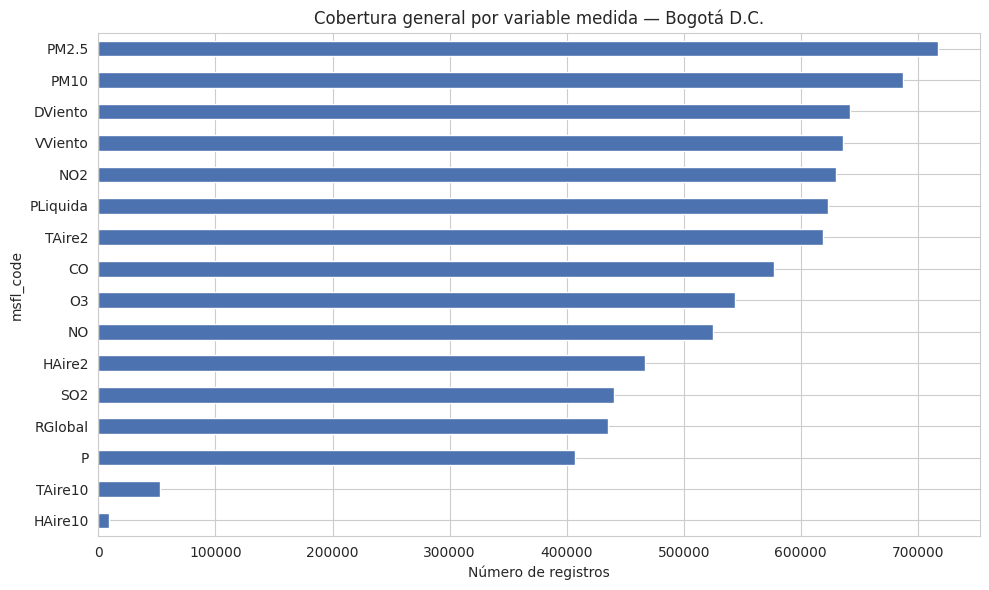

In [6]:
cobertura_variable = df['msfl_code'].value_counts()

print('Registros totales por variable (msfl_code) — toda Bogotá:')
print(cobertura_variable)

fig, ax = plt.subplots(figsize=(10, 6))
cobertura_variable.sort_values().plot(kind='barh', ax=ax, color='#4C72B0')
ax.set_xlabel('Número de registros')
ax.set_title('Cobertura general por variable medida — Bogotá D.C.')
plt.tight_layout()
plt.show()

---

## Sección 5: Cobertura de estaciones para PM2.5

**Qué se hace:** Se filtra únicamente PM2.5 (la variable objetivo del proyecto) y se cuentan registros por estación.

**Por qué:** PM2.5 es el eje central — sin buena cobertura de PM2.5, ninguna estación sirve, sin importar qué tan completa sea su meteorología. Esta es la primera criba antes de evaluar las demás variables.

Estaciones con al menos un registro de PM2.5: 22
nombre_est
FONTIBÓN                39531
PUENTE ARANDA           39375
GUAYMARAL               38837
KENNEDY                 38741
C. ALTO RENDIMIENTO     38688
SUBA                    38534
TUNAL                   38375
MINAMBIENTE             38239
LAS FERIAS              37855
MOCHUELO                37125
SAN CRISTÓBAL           36579
CIUDAD BOLIVAR          34397
EL JAZMÍN               33996
USAQUÉN                 33510
MÓVIL 7MA               32491
USME                    31970
BOLIVIA                 30392
MÓVIL FONTIBÓN          28965
CARVAJAL - SEVILLANA    27938
COLINA                  27748
MOCHUELO COL             7725
BOSA                     6198
Name: count, dtype: int64


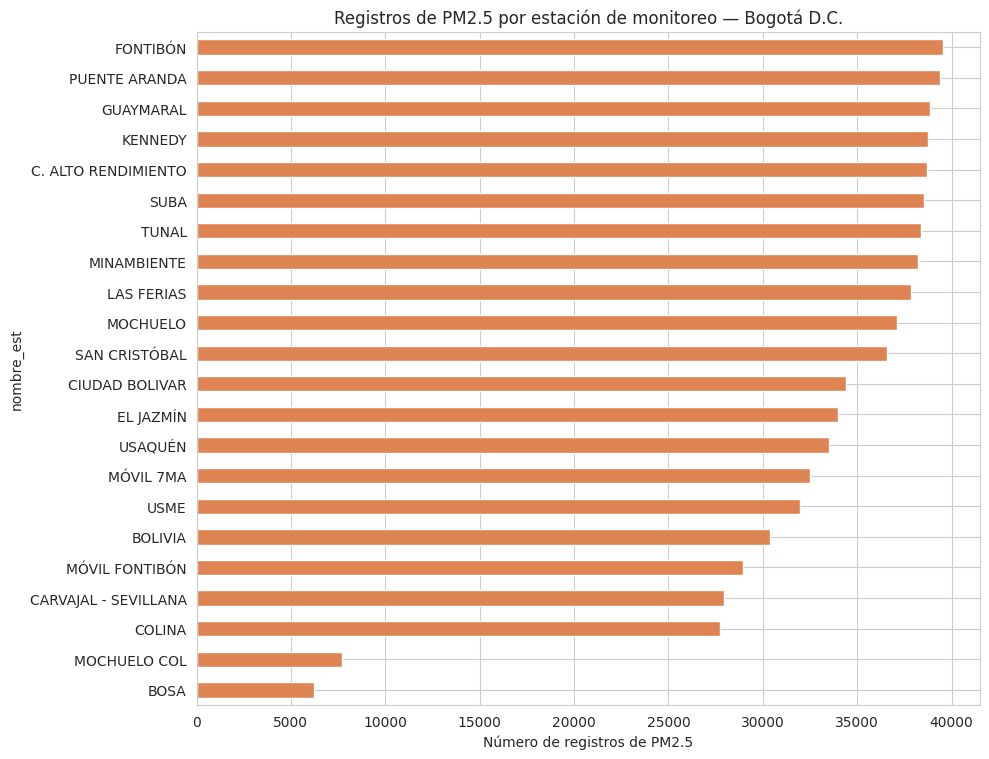

In [7]:
df_pm25 = df[df['msfl_code'] == 'PM2.5'].copy()
cobertura_pm25_estacion = df_pm25['nombre_est'].value_counts()

print(f'Estaciones con al menos un registro de PM2.5: {len(cobertura_pm25_estacion)}')
print(cobertura_pm25_estacion)

fig, ax = plt.subplots(figsize=(10, max(4, 0.35 * len(cobertura_pm25_estacion))))
cobertura_pm25_estacion.sort_values().plot(kind='barh', ax=ax, color='#DD8452')
ax.set_xlabel('Número de registros de PM2.5')
ax.set_title('Registros de PM2.5 por estación de monitoreo — Bogotá D.C.')
plt.tight_layout()
plt.show()

### 5.1 Rango temporal y densidad de la serie de PM2.5 por estación

**Qué se hace:** Para cada estación con PM2.5 se calcula la fecha de inicio, la fecha final, el número de registros, y `pct_cobertura` = registros observados / horas esperadas en ese rango.

**Por qué:** El número absoluto de registros puede engañar — una estación puede tener muchos registros pero repartidos en un rango temporal enorme con huecos grandes. `pct_cobertura` es una cota superior optimista (no detecta huecos internos cortos), pero permite descartar rápidamente estaciones con series demasiado dispersas o discontinuas, replicando la lógica de "serie horaria continua" que exige un Transformer.

In [8]:
resumen_pm25_estacion = (
    df_pm25
    .groupby('nombre_est')['med_fecha_inicio']
    .agg(primera_fecha='min', ultima_fecha='max', n_registros='count')
)
resumen_pm25_estacion['dias_span'] = (
    (resumen_pm25_estacion['ultima_fecha'] - resumen_pm25_estacion['primera_fecha']).dt.days + 1
)
resumen_pm25_estacion['horas_esperadas'] = resumen_pm25_estacion['dias_span'] * 24
resumen_pm25_estacion['pct_cobertura'] = (
    resumen_pm25_estacion['n_registros'] / resumen_pm25_estacion['horas_esperadas'] * 100
).round(1)

resumen_pm25_estacion = resumen_pm25_estacion.sort_values('n_registros', ascending=False)
resumen_pm25_estacion

,primera_fecha,ultima_fecha,n_registros,dias_span,horas_esperadas,pct_cobertura
nombre_est,,,,,,
FONTIBÓN,2020-01-01 01:00:00,2024-12-31 22:00:00,39531,1827,43848,90.20
PUENTE ARANDA,2020-01-01 01:00:00,2024-12-31 22:00:00,39375,1827,43848,89.80
GUAYMARAL,2020-01-01 01:00:00,2024-12-31 22:00:00,38837,1827,43848,88.60
KENNEDY,2020-01-01 10:00:00,2024-12-31 22:00:00,38741,1827,43848,88.40
C. ALTO RENDIMIENTO,2020-01-01 01:00:00,2024-12-31 22:00:00,38688,1827,43848,88.20
SUBA,2020-01-01 05:00:00,2024-12-31 22:00:00,38534,1827,43848,87.90
TUNAL,2020-01-01 01:00:00,2024-12-31 22:00:00,38375,1827,43848,87.50
MINAMBIENTE,2020-01-01 01:00:00,2024-12-31 22:00:00,38239,1827,43848,87.20
LAS FERIAS,2020-01-01 03:00:00,2024-12-31 22:00:00,37855,1827,43848,86.30


---

## Sección 6: Matriz estación × variable para las variables de la réplica

**Qué se hace:** Se restringe el dataset a las variables que mapean directamente a las ocho del paper de referencia (`PM2.5`, `TAire2`/`TAire10`, `HAire2`/`HAire10`, `P`, `DViento`, `VViento`, `PLiquida`) y se construye una matriz de conteo estación × variable.

**Por qué:** Para poder pivotear a formato ancho (una fila por hora, una columna por variable — el formato que exige el Transformer), **todas** las variables deben coexistir en la misma estación. Ver la cobertura de cada variable por separado (Sección 4) no basta; hace falta ver si una misma estación las tiene todas.

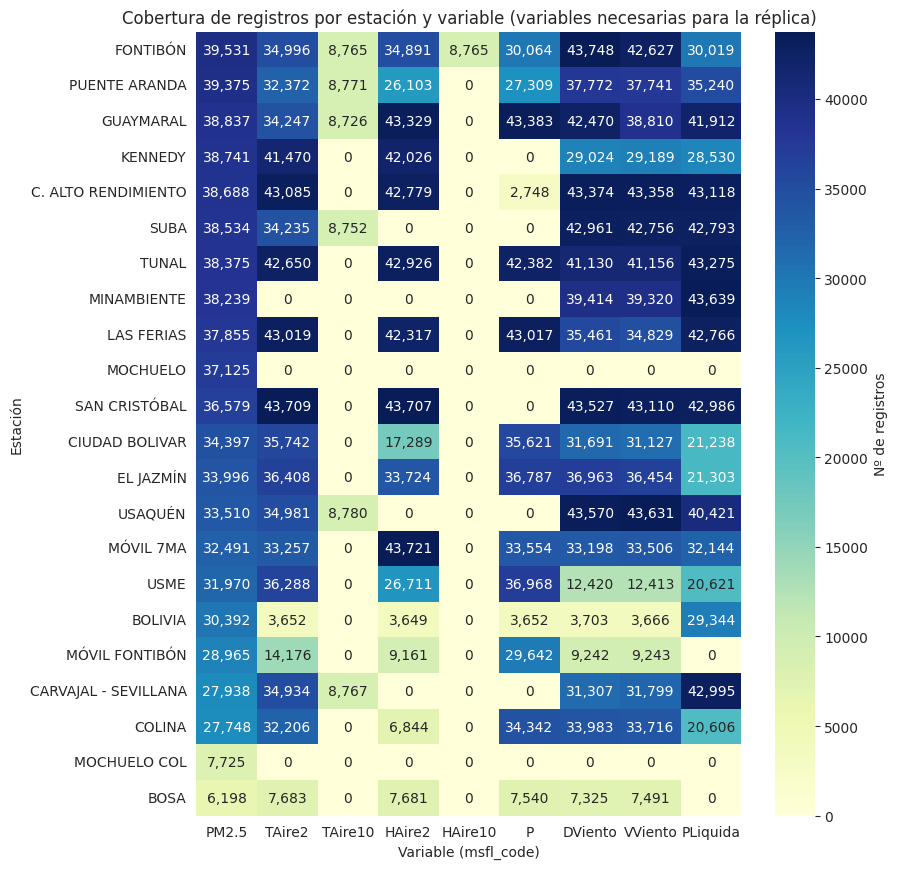

msfl_code,PM2.5,TAire2,TAire10,HAire2,HAire10,P,DViento,VViento,PLiquida
nombre_est,,,,,,,,,
FONTIBÓN,39531,34996,8765,34891,8765,30064,43748,42627,30019
PUENTE ARANDA,39375,32372,8771,26103,0,27309,37772,37741,35240
GUAYMARAL,38837,34247,8726,43329,0,43383,42470,38810,41912
KENNEDY,38741,41470,0,42026,0,0,29024,29189,28530
C. ALTO RENDIMIENTO,38688,43085,0,42779,0,2748,43374,43358,43118
SUBA,38534,34235,8752,0,0,0,42961,42756,42793
TUNAL,38375,42650,0,42926,0,42382,41130,41156,43275
MINAMBIENTE,38239,0,0,0,0,0,39414,39320,43639
LAS FERIAS,37855,43019,0,42317,0,43017,35461,34829,42766


In [9]:
VARIABLES_REPLICA = [
    'PM2.5', 'TAire2', 'TAire10', 'HAire2', 'HAire10',
    'P', 'DViento', 'VViento', 'PLiquida'
]

df_replica = df[df['msfl_code'].isin(VARIABLES_REPLICA)].copy()

matriz_estacion_variable = (
    df_replica
    .pivot_table(
        index='nombre_est', columns='msfl_code',
        values='med_concentracion_estandar', aggfunc='count', fill_value=0
    )
    .reindex(columns=VARIABLES_REPLICA, fill_value=0)
)

# Ordenar por disponibilidad de PM2.5, el eje central del proyecto
matriz_estacion_variable = matriz_estacion_variable.sort_values('PM2.5', ascending=False)

fig, ax = plt.subplots(figsize=(9, max(4, 0.4 * len(matriz_estacion_variable))))
sns.heatmap(
    matriz_estacion_variable, annot=True, fmt=',.0f', cmap='YlGnBu',
    cbar_kws={'label': 'Nº de registros'}, ax=ax
)
ax.set_title('Cobertura de registros por estación y variable (variables necesarias para la réplica)')
ax.set_xlabel('Variable (msfl_code)')
ax.set_ylabel('Estación')
plt.tight_layout()
plt.show()

matriz_estacion_variable

### 6.1 Puntaje de estaciones: variable "cuello de botella"

**Qué se hace:** Para cada estación se calcula (a) cuántas de las 9 variables tiene disponibles (usando la mejor entre `TAire2`/`TAire10` y entre `HAire2`/`HAire10`, ya que basta con una altura de cada una), y (b) el número de registros de la variable **más escasa** (`cuello_botella`).

**Por qué:** Tras pivotear a formato ancho, el número de filas *completas* que se pueden construir está limitado por la variable con menos registros — de nada sirve tener 40.000 registros de PM2.5 si la presión solo tiene 200. Este puntaje aproxima, sin pivotear todavía, cuántas horas realmente utilizables tendría cada estación.

In [10]:
VARS_TEMP = ['TAire2', 'TAire10']   # basta con una de las dos alturas
VARS_HUM = ['HAire2', 'HAire10']    # basta con una de las dos alturas
VARS_FIJAS = ['PM2.5', 'P', 'DViento', 'VViento', 'PLiquida']


def mejor_disponible(fila, opciones):
    return max(fila[o] for o in opciones)


puntaje = matriz_estacion_variable.copy()
puntaje['TEMP_max'] = puntaje.apply(lambda r: mejor_disponible(r, VARS_TEMP), axis=1)
puntaje['HUM_max'] = puntaje.apply(lambda r: mejor_disponible(r, VARS_HUM), axis=1)

columnas_cuello_botella = VARS_FIJAS + ['TEMP_max', 'HUM_max']
puntaje['cuello_botella'] = puntaje[columnas_cuello_botella].min(axis=1)
puntaje['n_variables_con_datos'] = (matriz_estacion_variable[VARIABLES_REPLICA] > 0).sum(axis=1)

ranking_estaciones = (
    puntaje[['PM2.5', 'n_variables_con_datos', 'cuello_botella']]
    .sort_values(['n_variables_con_datos', 'cuello_botella'], ascending=[False, False])
)
ranking_estaciones

msfl_code,PM2.5,n_variables_con_datos,cuello_botella
nombre_est,,,
FONTIBÓN,39531,9,30019
GUAYMARAL,38837,8,34247
PUENTE ARANDA,39375,8,26103
TUNAL,38375,7,38375
LAS FERIAS,37855,7,34829
MÓVIL 7MA,32491,7,32144
EL JAZMÍN,33996,7,21303
CIUDAD BOLIVAR,34397,7,17289
USME,31970,7,12413


### 6.2 Traslape temporal entre variables en las estaciones candidatas

**Qué se hace:** Para las estaciones mejor puntuadas, se calcula la intersección de rangos de fechas entre todas sus variables disponibles: la fecha de inicio más tardía entre variables, y la fecha final más temprana.

**Por qué:** Dos variables pueden tener muchos registros mirándolas por separado, pero si una empezó a medirse en 2016 y la otra dejó de medirse en 2019, la ventana **común** utilizable para el Transformer es mucho más corta que cualquiera de las dos por separado. Esta es la comprobación final antes de recomendar una estación.

In [11]:
N_CANDIDATAS = 5
estaciones_candidatas = ranking_estaciones.head(N_CANDIDATAS).index.tolist()
print('Estaciones candidatas evaluadas en detalle:', estaciones_candidatas)
print()

filas_traslape = []
for est in estaciones_candidatas:
    sub = df_replica[df_replica['nombre_est'] == est]
    rangos = sub.groupby('msfl_code')['med_fecha_inicio'].agg(['min', 'max'])
    if rangos.empty:
        continue
    inicio_comun = rangos['min'].max()
    fin_comun = rangos['max'].min()
    dias_comunes = max((fin_comun - inicio_comun).days, 0)
    filas_traslape.append({
        'estacion': est,
        'inicio_traslape': inicio_comun,
        'fin_traslape': fin_comun,
        'dias_traslape': dias_comunes
    })

tabla_traslape = pd.DataFrame(filas_traslape).sort_values('dias_traslape', ascending=False)
tabla_traslape

Estaciones candidatas evaluadas en detalle: ['FONTIBÓN', 'GUAYMARAL', 'PUENTE ARANDA', 'TUNAL', 'LAS FERIAS']



,estacion,inicio_traslape,fin_traslape,dias_traslape
3,TUNAL,2020-01-01 01:00:00,2024-12-09 10:00:00,1804
4,LAS FERIAS,2020-01-01 03:00:00,2024-02-14 11:00:00,1505
0,FONTIBÓN,2021-07-14 13:00:00,2020-12-31 23:00:00,0
2,PUENTE ARANDA,2021-12-01 00:00:00,2020-12-31 23:00:00,0
1,GUAYMARAL,2021-01-01 00:00:00,2020-12-31 23:00:00,0


---

## Sección 7: Recomendación de estación para la réplica

**Qué se hace:** Se combina el ranking de cobertura (Sección 6.1) con el traslape temporal (Sección 6.2) para señalar la estación recomendada.

**Por qué:** Ninguna de las dos métricas por sí sola basta — cobertura sin traslape temporal produce una ventana usable engañosamente corta, y traslape sin cobertura suficiente produce una serie con muchos huecos internos.

In [12]:
estacion_recomendada = ranking_estaciones.index[0]

print('=' * 70)
print('ESTACIÓN RECOMENDADA PARA LA RÉPLICA:', estacion_recomendada)
print('=' * 70)
print(f"Registros de PM2.5             : {ranking_estaciones.loc[estacion_recomendada, 'PM2.5']:,.0f}")
print(f"Variables disponibles (de {len(VARIABLES_REPLICA)}) : {ranking_estaciones.loc[estacion_recomendada, 'n_variables_con_datos']:.0f}")
print(f"Cuello de botella (registros)  : {ranking_estaciones.loc[estacion_recomendada, 'cuello_botella']:,.0f}")

if estacion_recomendada in tabla_traslape['estacion'].values:
    fila = tabla_traslape.set_index('estacion').loc[estacion_recomendada]
    print(
        f"Ventana con TODAS las variables simultáneas: "
        f"{fila['inicio_traslape'].date()} a {fila['fin_traslape'].date()} "
        f"({fila['dias_traslape']:,} días)"
    )
else:
    print('Ventana con todas las variables simultáneas: no calculada (fuera del top de candidatas evaluadas).')

print()
print('Top 5 estaciones por puntaje (referencia):')
ranking_estaciones.head(5)

ESTACIÓN RECOMENDADA PARA LA RÉPLICA: FONTIBÓN
Registros de PM2.5             : 39,531
Variables disponibles (de 9) : 9
Cuello de botella (registros)  : 30,019
Ventana con TODAS las variables simultáneas: 2021-07-14 a 2020-12-31 (0 días)

Top 5 estaciones por puntaje (referencia):


msfl_code,PM2.5,n_variables_con_datos,cuello_botella
nombre_est,,,
FONTIBÓN,39531,9,30019
GUAYMARAL,38837,8,34247
PUENTE ARANDA,39375,8,26103
TUNAL,38375,7,38375
LAS FERIAS,37855,7,34829


### 7.1 Estrategia alternativa: combinar estaciones (si ninguna es completa)

Si la Sección 6.1 muestra que **ninguna estación individual** tiene las 9 variables con cobertura suficiente, no es necesario descartar el proyecto: el propio paper de referencia sienta el precedente de combinar fuentes. El dataset de Beijing combina la concentración de PM2.5 medida en la Embajada de EE. UU. con la meteorología de un aeropuerto distinto — es decir, **PM2.5 y meteorología no tienen por qué venir de la misma estación física**, siempre que:

- la estación meteorológica esté razonablemente cerca de la estación de PM2.5 (para que la meteorología sea representativa), y
- ambas series se puedan alinear por hora sin generar demasiados huecos.

En ese caso, la recomendación sería: **una estación con la mejor serie de PM2.5** (ver Sección 5.1) + **la estación con mejor meteorología completa más cercana** (ver mapa de coordenadas si el dataset las incluye). Esta decisión debe documentarse explícitamente, igual que se documentó la omisión de nieve por la altitud de Bogotá.

---

## Sección 8: Guardado de resultados para el siguiente cuaderno

**Qué se hace:** Se guardan las tablas de cobertura y el subconjunto crudo (todas las variables) de la estación recomendada, para que el siguiente cuaderno (transformación largo → ancho) no tenga que repetir la descarga ni el análisis de selección.

In [13]:
OUT_DIR = 'outputs'
os.makedirs(OUT_DIR, exist_ok=True)

matriz_estacion_variable.to_csv(os.path.join(OUT_DIR, 'matriz_cobertura_estacion_variable.csv'))
ranking_estaciones.to_csv(os.path.join(OUT_DIR, 'ranking_estaciones_pm25.csv'))
resumen_pm25_estacion.to_csv(os.path.join(OUT_DIR, 'resumen_temporal_pm25_estacion.csv'))

nombre_archivo_estacion = estacion_recomendada.replace(' ', '_').replace('/', '-')
df_estacion_elegida = df[df['nombre_est'] == estacion_recomendada].copy()
df_estacion_elegida.to_csv(
    os.path.join(OUT_DIR, f'bogota_{nombre_archivo_estacion}_todas_variables.csv'),
    index=False
)

print(f'Archivos guardados en {OUT_DIR}/:')
for f in sorted(os.listdir(OUT_DIR)):
    print(' -', f)

Archivos guardados en outputs/:
 - bogota_FONTIBÓN_todas_variables.csv
 - matriz_cobertura_estacion_variable.csv
 - ranking_estaciones_pm25.csv
 - resumen_temporal_pm25_estacion.csv


---

## Sección 9: Próximos pasos

Con la estación (o combinación de estaciones) seleccionada en este cuaderno, el siguiente paso es construir el pipeline de transformación largo → ancho, aplicando el mapeo de variables ya definido para el proyecto:

| Variable Beijing (paper) | Variable Bogotá (RMCAB) | Transformación |
|---|---|---|
| `pm2.5` | `PM2.5` | Directo (variable objetivo) |
| `TEMP` | `TAire2` / `TAire10` | Directo (elegir una altura y ser consistente) |
| `PRES` | `P` | mmHg → hPa (× 1.333) |
| `DEWP` | `TAire2` + `HAire2` | Fórmula de Magnus |
| `cbwd` | `DViento` | Codificación cíclica seno/coseno |
| `Iws` | `VViento` | Uso directo (instantáneo) o acumulación aproximada |
| `Ir` | `PLiquida` | Indicador binario (`PLiquida > 0`) |
| `Is` | — | Omitida (Bogotá no presenta nieve por su altitud) |

Y luego: pivote largo → ancho por estación, reindexado horario con `pd.date_range`, interpolación lineal / bounded fill para huecos cortos, y recorte documentado (no interpolado) de huecos largos.

---

## Notas y limitaciones de este cuaderno

- **Disponibilidad dinámica de datos.** El portal datos.gov.co actualiza el recurso `g4t8-zkc3` continuamente; los conteos exactos de este cuaderno pueden variar según la fecha de ejecución. Vuelve a ejecutar la celda de descarga (o borra el caché local) antes de tomar la decisión final de estación.
- **Cobertura ≠ calidad.** Un número alto de registros no garantiza ausencia de valores atípicos, saturación del sensor o pequeños huecos internos. Esa limpieza fina se hace en el siguiente cuaderno, ya con la estación decidida.
- **`pct_cobertura` es una cota superior optimista.** Se calcula como registros observados / horas esperadas en el rango [primera, última fecha], por lo que no detecta huecos internos cortos; solo permite descartar rápidamente estaciones con series demasiado dispersas o cortas.
- **Requiere conexión a internet.** La celda de descarga consulta la API pública de datos.gov.co. Si se ejecuta sin conexión, debe existir previamente el archivo de caché en `data/bogota_calidad_aire_raw.parquet`.
